Practical: K-Means Clustering on a Multidimensional UCI Dataset

In [2]:
!pip install ucimlrepo

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [4]:
# Fetch Wholesale Customers dataset from UCI
wholesale = fetch_ucirepo(id=292)

# Get dataset features
df = wholesale.data.features

# Display first five rows
print(df.head())

   Channel  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2  12669  9656     7561     214              2674        1338
1        2   7057  9810     9568    1762              3293        1776
2        2   6353  8808     7684    2405              3516        7844
3        1  13265  1196     4221    6404               507        1788
4        2  22615  5410     7198    3915              1777        5185


In [5]:
# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (440, 7)

Column Names:
Index(['Channel', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper',
       'Delicassen'],
      dtype='object')

Missing Values:
Channel             0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Statistical Summary:
          Channel          Fresh          Milk       Grocery        Frozen  \
count  440.000000     440.000000    440.000000    440.000000    440.000000   
mean     1.322727   12000.297727   5796.265909   7951.277273   3071.931818   
std      0.468052   12647.328865   7380.377175   9503.162829   4854.673333   
min      1.000000       3.000000     55.000000      3.000000     25.000000   
25%      1.000000    3127.750000   1533.000000   2153.000000    742.250000   
50%      1.000000    8504.000000   3627.000000   4755.500000   1526.000000   
75%      2.000000   16933.750000   7190.250000  10655.750000   3554.250000   
max      2.

In [6]:
features = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicassen'
]

X = df[features]

print(X.head())
print("\nSelected Features:", X.shape)

   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844
3  13265  1196     4221    6404               507        1788
4  22615  5410     7198    3915              1777        5185

Selected Features: (440, 6)


In [7]:
# Apply log transformation
X_log = np.log1p(X)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled Data:")
print(X_scaled[:5])

Scaled Data:
[[ 0.4861845   0.97629884  0.44015468 -1.50924981  0.64414327  0.40896595]
 [ 0.08788863  0.99095612  0.65217085  0.13405226  0.76604314  0.62792606]
 [ 0.01635628  0.89115098  0.45468702  0.37689926  0.80440496  1.77683339]
 [ 0.51747725 -0.95797283 -0.08479166  1.14157433 -0.3287115   0.63313326]
 [ 0.8806309   0.43966195  0.39584651  0.75732216  0.40493851  1.4565879 ]]


In [8]:
inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Display scores
for k, score in zip(k_values, silhouette_scores):
    print("Clusters:", k, "Silhouette Score:", round(score, 4))

Clusters: 2 Silhouette Score: 0.2903
Clusters: 3 Silhouette Score: 0.2594
Clusters: 4 Silhouette Score: 0.1885
Clusters: 5 Silhouette Score: 0.1916
Clusters: 6 Silhouette Score: 0.2009
Clusters: 7 Silhouette Score: 0.1958
Clusters: 8 Silhouette Score: 0.1852
Clusters: 9 Silhouette Score: 0.1965
Clusters: 10 Silhouette Score: 0.1905


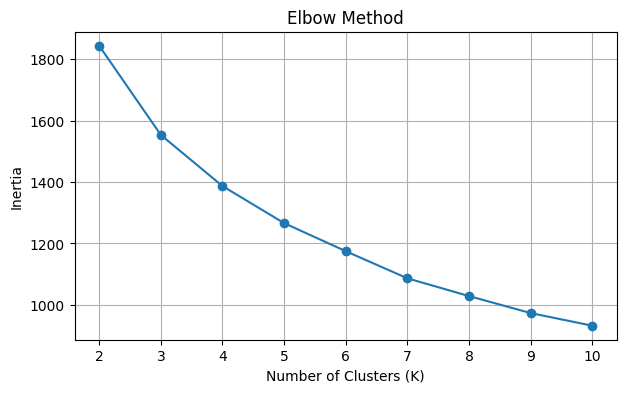

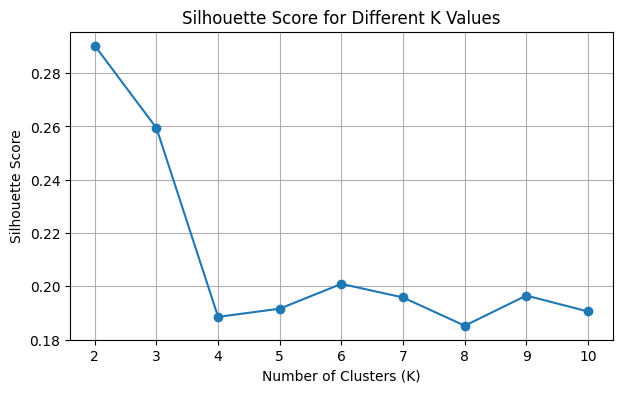

In [9]:
# Elbow Method
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid()
plt.show()

# Silhouette Score
plt.figure(figsize=(7, 4))
plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.grid()
plt.show()

In [10]:
# Select K with the highest silhouette score
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Best Number of Clusters:", best_k)

# Create and train K-Means model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)

# Assign cluster labels
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df_result = X.copy()
df_result['Cluster'] = cluster_labels

print(df_result.head())

Best Number of Clusters: 2
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Cluster
0  12669  9656     7561     214              2674        1338        1
1   7057  9810     9568    1762              3293        1776        1
2   6353  8808     7684    2405              3516        7844        1
3  13265  1196     4221    6404               507        1788        0
4  22615  5410     7198    3915              1777        5185        1


In [11]:
score = silhouette_score(X_scaled, cluster_labels)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.2903


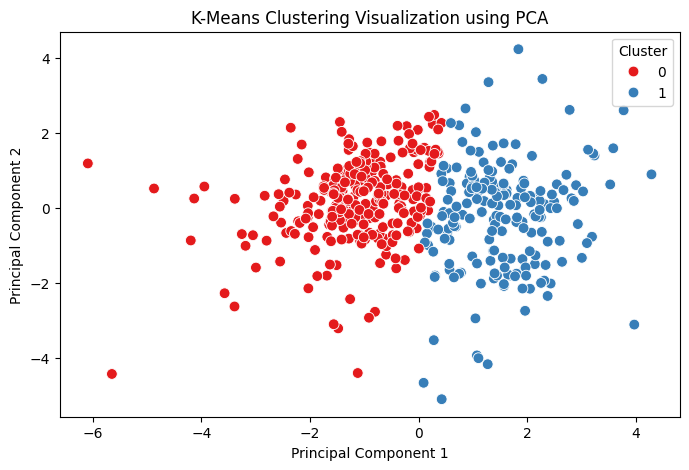

In [12]:
# Reduce data to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for visualization
pca_df = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
pca_df['Cluster'] = cluster_labels

# Plot clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    s=60
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [13]:
# Count customers in each cluster
print("Customers in Each Cluster:")
print(df_result['Cluster'].value_counts().sort_index())

# Calculate average spending in each cluster
cluster_analysis = df_result.groupby('Cluster')[features].mean()

print("\nAverage Spending of Each Cluster:")
print(cluster_analysis.round(2))

Customers in Each Cluster:
Cluster
0    252
1    188
Name: count, dtype: int64

Average Spending of Each Cluster:
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0        13973.13   2401.75   2918.71  3705.67            491.94     1038.04
1         9355.87  10346.36  14697.06  2222.45           6084.51     2177.43
